In [1]:
from pathlib import Path
from sys import displayhook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid")

In [19]:
data_dir = Path("data/synthetic_raw")
members_raw = pd.read_csv(data_dir / "members.csv")
contracts_raw = pd.read_csv(data_dir / "contracts.csv")
check_ins_raw = pd.read_csv(data_dir / "check_ins.csv")

contracts_raw["start_date"] = pd.to_datetime(contracts_raw["start_date"])
contracts_raw["end_date"] = pd.to_datetime(contracts_raw["end_date"])
check_ins_raw["timestamp"] = pd.to_datetime(check_ins_raw["timestamp"])

check_ins_clean = check_ins_raw.sort_values(["member_id", "timestamp"]).copy()
check_ins_clean["time_since_last"] = check_ins_clean.groupby("member_id")["timestamp"].diff()

is_duplicate_noise = check_ins_clean["time_since_last"] < pd.Timedelta(minutes=45)
n_removed = is_duplicate_noise.sum()

check_ins_clean = check_ins_clean[~is_duplicate_noise].drop(columns=["time_since_last"]).reset_index(drop=True)

print(f"Raw check ins at the gate {len(check_ins_raw)}")
print(f"Removed false check ins (< 45 minutes): {n_removed} ({n_removed / len(check_ins_raw):.2%})")
print(f"Clean training visits: {len(check_ins_clean)}")

Raw check ins at the gate 36760
Removed false check ins (< 45 minutes): 1588 (4.32%)
Clean training visits: 35172


In [21]:
ANALYSIS_DATE = pd.Timestamp("2025-12-29")

contracts_sorted = contracts_raw.sort_values(["member_id", "start_date"]).copy()
contracts_sorted["prev_end_date"] = contracts_sorted.groupby("member_id")["end_date"].shift(1)

contracts_sorted["gap_days"] = (contracts_sorted["start_date"] - contracts_sorted["prev_end_date"]).dt.days

contracts_sorted["is_new_episode"] = (
    contracts_sorted["gap_days"].isna() | (contracts_sorted["gap_days"] > 21)
).astype(int)

contracts_sorted["member_episode_num"] = contracts_sorted.groupby("member_id")["is_new_episode"].cumsum()
contracts_sorted["episode_id"] = contracts_sorted.groupby(["member_id", "member_episode_num"]).ngroup() + 1

episodes_df = (
    contracts_sorted.groupby(["episode_id", "member_id", "member_episode_num"], as_index=False)
    .agg(
        episode_start=("start_date", "min"),
        contract_end=("end_date", "max"),
        n_contracts=("contract_id", "count"),
        initial_duration_months=("duration_months", "first"),
        last_duration_months=("duration_months", "last"),
        avg_monthly_price=("monthly_price", "mean"),
        final_status=("status", "last"),
    )
)
episodes_df["final_status"] = episodes_df["final_status"].replace({"renewed": "active"})

episodes_df["observed_end"] = episodes_df["contract_end"].clip(upper=ANALYSIS_DATE)

episodes_df["observed_weeks"] = ((episodes_df["observed_end"] - episodes_df["episode_start"]).dt.days // 7)

episodes_df["weeks_to_contract_end"] = (
    (episodes_df["contract_end"] - ANALYSIS_DATE).dt.days // 7
).clip(lower=0)

episodes_df["is_returning"] = (episodes_df["member_episode_num"] > 1).astype(int)

episodes_df = episodes_df.merge(members_raw, on="member_id", how="left")

episodes_df = episodes_df[episodes_df["observed_weeks"] > 0].reset_index(drop=True)

print(f"Number of clients (members): {len(members_raw)}")
print(f"Number of detected episodes: {len(episodes_df)}")
print(f"Number of returns after a longer break: {episodes_df["is_returning"].sum()}")
print("\nDistribution of episode final status:")
print(episodes_df["final_status"].value_counts())

display(episodes_df.head(10))

Number of clients (members): 500
Number of detected episodes: 556
Number of returns after a longer break: 56

Distribution of episode final status:
final_status
churned    401
active     155
Name: count, dtype: int64


,episode_id,member_id,member_episode_num,episode_start,contract_end,n_contracts,initial_duration_months,last_duration_months,avg_monthly_price,final_status,observed_end,observed_weeks,weeks_to_contract_end,is_returning,age,distance_km,promo_friends,partners_company
0,1,1,1,2025-03-17,2025-09-29,2,6,1,184.000,churned,2025-09-29,28,0,0,32,3.39,0,0
1,2,2,1,2024-12-09,2025-08-25,4,1,6,162.775,churned,2025-08-25,37,0,0,37,4.21,0,1
2,3,3,1,2024-04-01,2025-03-03,1,12,12,139.000,churned,2025-03-03,48,0,0,23,4.31,1,0
3,4,4,1,2025-04-21,2026-03-23,1,12,12,118.150,active,2025-12-29,36,12,0,45,2.29,0,1
4,5,5,1,2024-08-05,2025-12-08,6,1,12,189.000,churned,2025-12-08,70,0,0,29,1.11,0,0
5,6,6,1,2024-07-22,2025-06-23,1,12,12,139.000,churned,2025-06-23,48,0,0,24,0.89,0,0
6,7,7,1,2024-03-25,2024-04-22,1,1,1,199.000,churned,2024-04-22,4,0,0,42,0.65,1,0
7,8,8,1,2024-02-05,2024-12-09,6,1,6,194.000,churned,2024-12-09,44,0,0,28,2.21,1,0
8,9,9,1,2024-02-26,2025-02-24,2,1,12,143.650,churned,2025-02-24,52,0,0,26,1.72,1,1
9,10,10,1,2024-09-30,2025-10-27,3,1,12,179.000,churned,2025-10-27,56,0,0,32,3.87,0,0


In [26]:
check_ins_ep = check_ins_clean.merge(
    episodes_df[["episode_id", "member_id", "episode_start", "observed_end"]],
    on="member_id",
    how="inner"
)
check_ins_ep = check_ins_ep[
    (check_ins_ep["timestamp"] >= check_ins_ep["episode_start"])
    & (check_ins_ep["timestamp"] < check_ins_ep["observed_end"])
]

check_ins_ep["t"] = ((check_ins_ep["timestamp"] - check_ins_ep["episode_start"]).dt.days // 7) + 1

weekly_counts = (
    check_ins_ep.groupby(["episode_id", "t"], as_index=False)
    .agg(
        visits=("timestamp", "count"),
        group_visits=("is_group_class", "sum"),
        weekly_spend=("additional_spend", "sum"),
    )
)

grid_rows = []
for row in episodes_df[["episode_id", "observed_weeks"]].itertuples(index=False):
    for t_val in range(1, row.observed_weeks + 1):
        grid_rows.append((row.episode_id, t_val))

weekly_grid_df = pd.DataFrame(grid_rows, columns=["episode_id", "t"])

weekly_grid_df = weekly_grid_df.merge(weekly_counts, on=["episode_id", "t"], how="left").fillna({
    "visits": 0,
    "group_visits": 0,
    "weekly_spend": 0.0,
})
weekly_grid_df["visits"] = weekly_grid_df["visits"].astype(int)
weekly_grid_df["group_visits"] = weekly_grid_df["group_visits"].astype(int)

ep_behavior_summary = (
    weekly_grid_df.groupby("episode_id", as_index=False)
    .agg(
        total_visits=("visits", "sum"),
        total_group_visits=("group_visits", "sum"),
        avg_weekly_spend=("weekly_spend", "mean"),
    )
)

ep_behavior_summary["group_affinity"] = (
    (ep_behavior_summary["total_group_visits"] + 1.0) / (ep_behavior_summary["total_visits"] + 2.0)
).round(3)

episodes_df = episodes_df.merge(ep_behavior_summary, on="episode_id", how="left")

print(f"Size of full weekly grid: {len(weekly_grid_df)}")
print(f"Amount of weeks with 0 visits: {(weekly_grid_df["visits"] == 0).mean():.2%}")
display(weekly_grid_df.head(12))
display(episodes_df[["episode_id", "member_id", "observed_weeks", "total_visits", "group_affinity", "final_status"]].head(10))

Size of full weekly grid: 21224
Amount of weeks with 0 visits: 41.00%


,episode_id,t,visits,group_visits,weekly_spend
0,1,1,2,0,0.00
1,1,2,2,0,28.50
2,1,3,3,0,0.00
3,1,4,3,0,0.00
4,1,5,0,0,0.00
5,1,6,3,0,0.91
6,1,7,4,0,0.00
7,1,8,2,0,0.00
8,1,9,1,0,0.00
9,1,10,3,0,0.00


,episode_id,member_id,observed_weeks,total_visits,group_affinity,final_status
0,1,1,28,60,0.016,churned
1,2,2,37,34,0.028,churned
2,3,3,48,43,0.022,churned
3,4,4,36,95,0.010,active
4,5,5,70,77,0.646,churned
5,6,6,48,139,0.007,churned
6,7,7,4,7,0.222,churned
7,8,8,44,82,0.012,churned
8,9,9,52,129,0.008,churned
9,10,10,56,42,0.023,churned


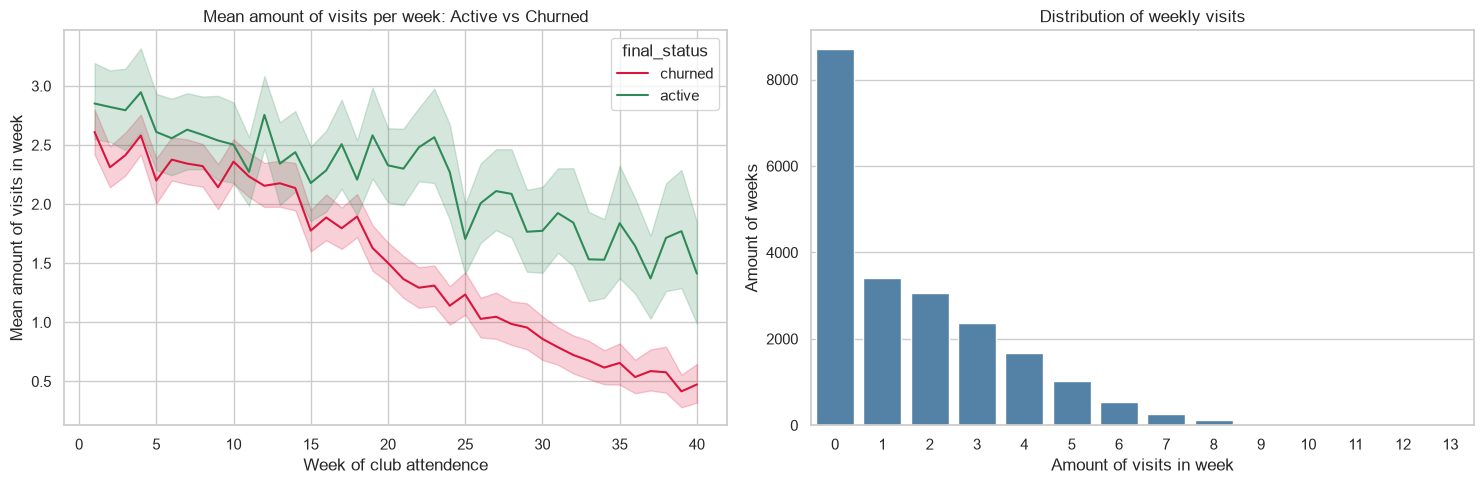

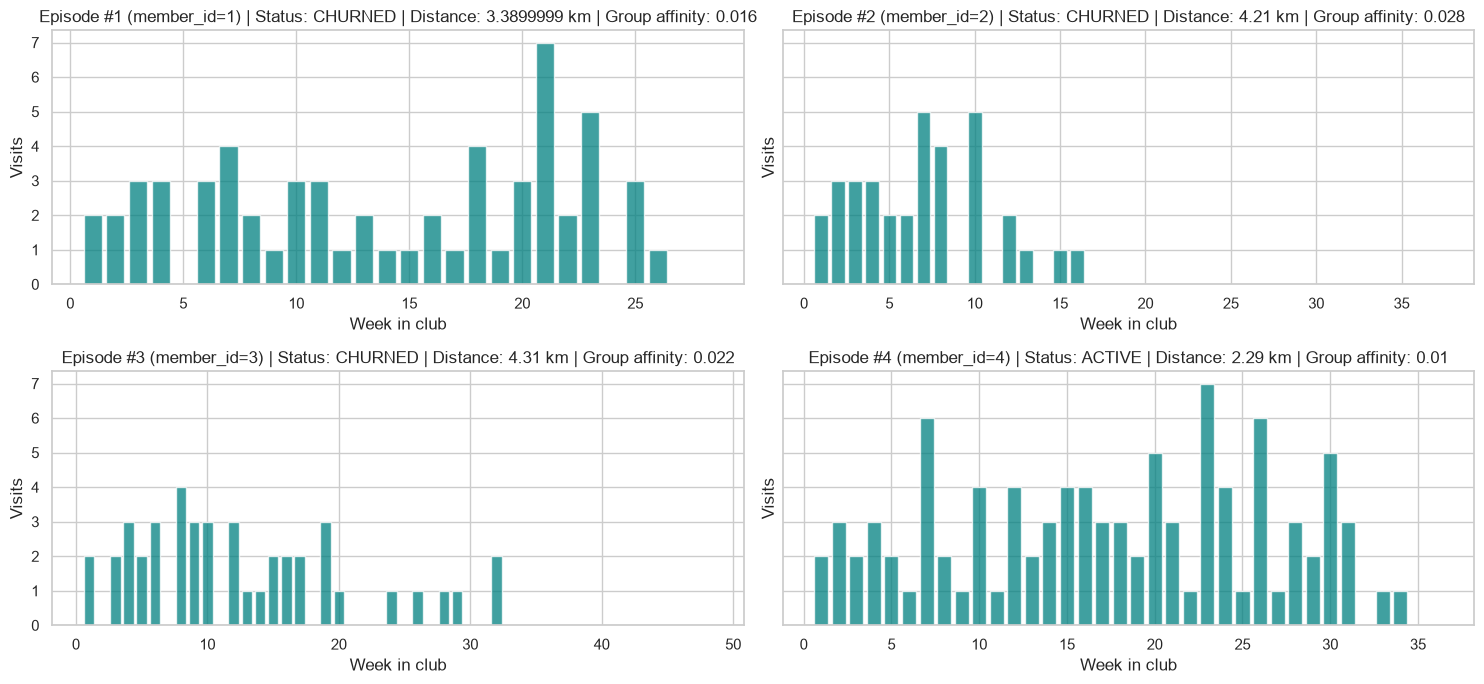

In [27]:
weekly_with_status = weekly_grid_df.merge(
    episodes_df[["episode_id", "final_status", "observed_weeks"]], on="episode_id", how="left"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

subset_40w = weekly_with_status[weekly_with_status["t"] <= 40]
sns.lineplot(
    data=subset_40w,
    x="t",
    y="visits",
    hue="final_status",
    palette={"active": "seagreen", "churned": "crimson"},
    ax=axes[0],
)
axes[0].set_title("Mean amount of visits per week: Active vs Churned")
axes[0].set_xlabel("Week of club attendence")
axes[0].set_ylabel("Mean amount of visits in week")

sns.countplot(data=weekly_grid_df, x="visits", color="steelblue", ax=axes[1])
axes[1].set_title("Distribution of weekly visits")
axes[1].set_xlabel("Amount of visits in week")
axes[1].set_ylabel("Amount of weeks")

plt.tight_layout()
plt.show()

sample_eps = episodes_df[episodes_df["observed_weeks"] >= 20].head(4)["episode_id"].tolist()
fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharey=True)

for ax, ep_id in zip(axes.flat, sample_eps):
    ep_data = weekly_grid_df[weekly_grid_df["episode_id"] == ep_id]
    ep_info = episodes_df[episodes_df["episode_id"] == ep_id].iloc[0]

    ax.bar(ep_data["t"], ep_data["visits"], color="teal", alpha=0.75, width=0.8)
    ax.set_title(
        f"Episode #{ep_id} (member_id={ep_info['member_id']}) | Status: {ep_info['final_status'].upper()} | "
        f"Distance: {ep_info['distance_km']} km | Group affinity: {ep_info['group_affinity']}"
    )
    ax.set_xlabel("Week in club")
    ax.set_ylabel("Visits")

plt.tight_layout()
plt.show()

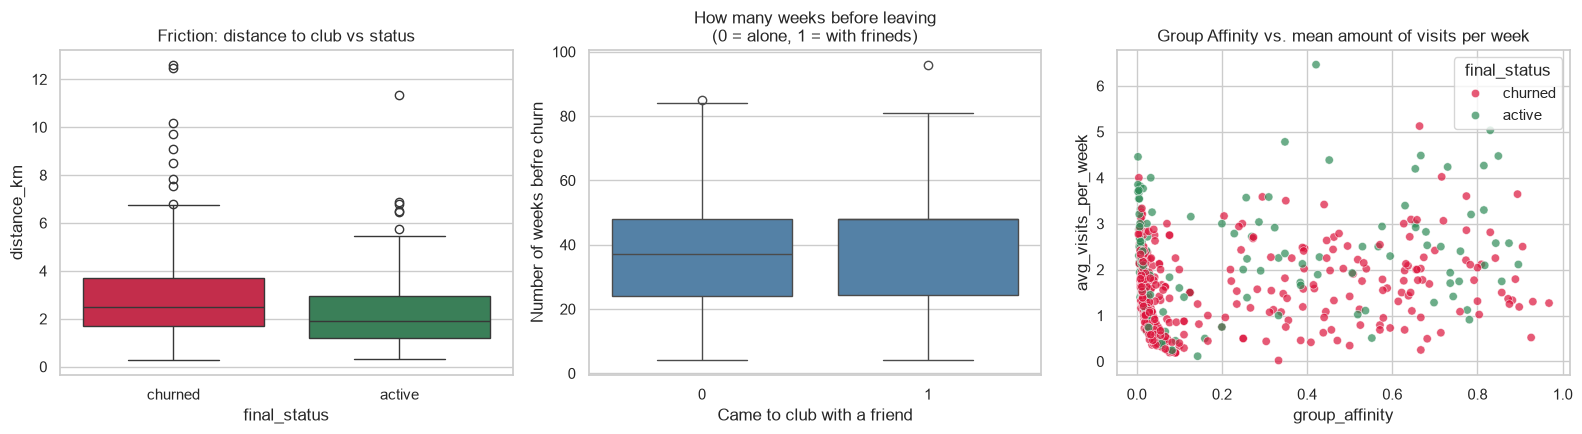

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.boxplot(
    data=episodes_df, x="final_status", y="distance_km",
    hue="final_status", palette={"active": "seagreen", "churned": "crimson"}, ax=axes[0]
)
axes[0].set_title("Friction: distance to club vs status")

sns.boxplot(
    data=episodes_df[episodes_df["final_status"] == "churned"],
    x="promo_friends", y="observed_weeks", color="steelblue", ax=axes[1]
)
axes[1].set_title("How many weeks before leaving\n(0 = alone, 1 = with frineds)")
axes[1].set_xlabel("Came to club with a friend")
axes[1].set_ylabel("Number of weeks befre churn")

episodes_df["avg_visits_per_week"] = episodes_df["total_visits"] / episodes_df["observed_weeks"]
sns.scatterplot(
    data=episodes_df, x="group_affinity", y="avg_visits_per_week",
    hue="final_status", palette={"active": "seagreen", "churned": "crimson"}, alpha=0.7, ax=axes[2]
)
axes[2].set_title("Group Affinity vs. mean amount of visits per week")

plt.tight_layout()
plt.show()

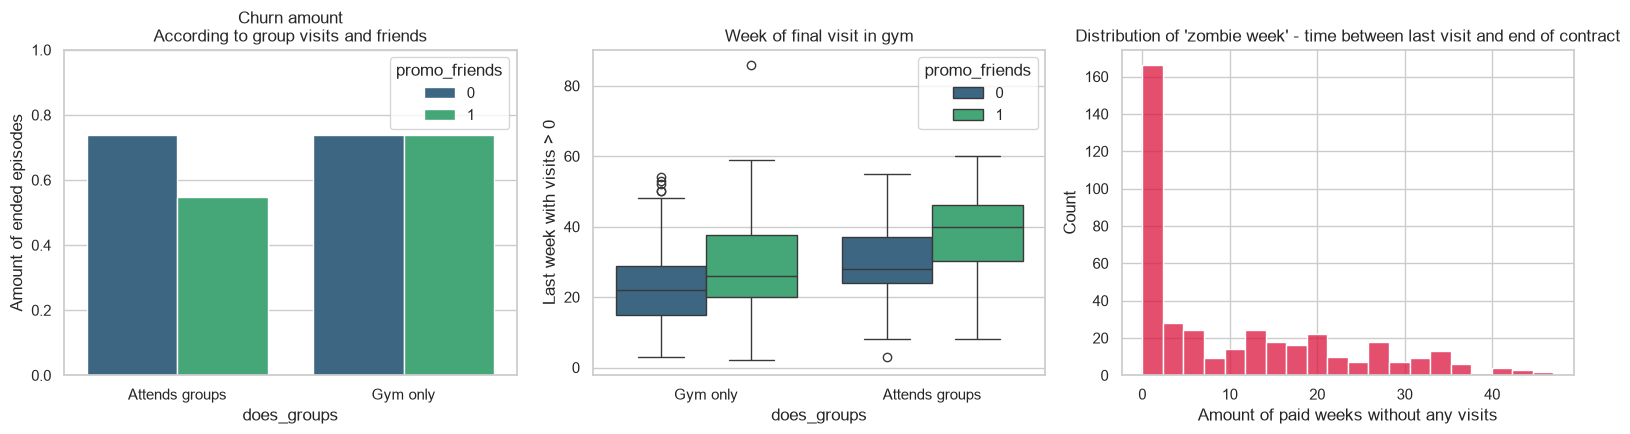

In [30]:
last_active_week = (
    weekly_grid_df[weekly_grid_df["visits"] > 0]
    .groupby("episode_id", as_index=False)["t"]
    .max()
    .rename(columns={"t": "last_visit_week"})
)

eda_behav = episodes_df.merge(last_active_week, on="episode_id", how="left")
eda_behav["last_visit_week"] = eda_behav["last_visit_week"].fillna(0)
eda_behav["zombie_weeks"] = eda_behav["observed_weeks"] - eda_behav["last_visit_week"]
eda_behav["does_groups"] = np.where(eda_behav["total_group_visits"] >= 3, "Attends groups", "Gym only")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

churn_rates = (
    eda_behav.assign(is_churned=(eda_behav["final_status"] == "churned").astype(int))
    .groupby(["promo_friends", "does_groups"], as_index=False)["is_churned"]
    .mean()
)
sns.barplot(
    data=churn_rates, x="does_groups", y="is_churned",
    hue="promo_friends", palette="viridis", ax=axes[0]
)
axes[0].set_title("Churn amount\nAccording to group visits and friends")
axes[0].set_ylabel("Amount of ended episodes")
axes[0].set_ylim(0, 1.0)

sns.boxplot(
    data=eda_behav[eda_behav["final_status"] == "churned"],
    x="does_groups", y="last_visit_week", hue="promo_friends", palette="viridis", ax=axes[1]
)
axes[1].set_title("Week of final visit in gym")
axes[1].set_ylabel("Last week with visits > 0")

sns.histplot(
    data=eda_behav[eda_behav["final_status"] == "churned"],
    x="zombie_weeks", bins=20, color="crimson", ax=axes[2]
)
axes[2].set_title("Distribution of 'zombie week' - time between last visit and end of contract")
axes[2].set_xlabel("Amount of paid weeks without any visits")

plt.tight_layout()
plt.show()

In [29]:
processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

episodes_df.to_csv(processed_dir / "episodes.csv", index=False)
weekly_grid_df.to_csv(processed_dir / "weekly_grid.csv", index=False)

print(f"Saved proccessed tables for moedling in: {processed_dir.resolve()}")
print(f"   - episodes.csv: {len(episodes_df)} rows")
print(f"   - weekly_grid.csv: {len(weekly_grid_df)} rows")

Saved proccessed tables for moedling in: C:\Users\milos\Desktop\Projects\gym-churn-project\notebooks\data\processed
   - episodes.csv: 556 rows
   - weekly_grid.csv: 21224 rows
